# Imports

In [28]:
import torch
import rasterio
from rasterio import features
import numpy as np
import matplotlib.pyplot as plt
import geopandas as gpd
import shapely
import pyproj
import glob
from torch import nn
from torch.utils.data import Dataset
from torch.utils.data import DataLoader
from os.path import join
import os
import random
# import albumentations as A
import torchvision
import pandas as pd
from rasterio.warp import reproject, Resampling
from matplotlib.patches import Patch
from matplotlib.colors import ListedColormap, BoundaryNorm

# TP1  
On veut dans un premier temps découper les datasets pour avoir des patches de 512*512

In [2]:
clc_path=r"data\input\clc_decoupe.shp"
clc=gpd.read_file(clc_path)

In [3]:
clc32631=clc.to_crs(crs=32631) #on reprojette corine land cover dans le crs de S2

## Lecture images S2

In [5]:
# définition d'une fonction de resampling pour pouvoir utiliser la bande B11 dans les visualisation suivantes

def read_band_resample(path, ref_shape, ref_transform, ref_crs):
    with rasterio.open(path) as src:
        data = src.read(1)

        dst = np.empty(ref_shape, dtype=np.float32)

        reproject(
            source=data,
            destination=dst,
            src_transform=src.transform,
            src_crs=src.crs,
            dst_transform=ref_transform,
            dst_crs=ref_crs,
            resampling=Resampling.bilinear
        )

    return dst

In [6]:
def get_s2(folder_path, bandes):
    files=[]
    for bande in bandes:
        glob_path=join(folder_path, f"*{bande}.tif") # on veut charger toutes les images satellites de nos bandes d'intérêt
        files.append(glob.glob(glob_path)[0])
    with rasterio.open(files[0]) as ref:
        ref_data = ref.read(1)
        ref_shape = ref_data.shape
        ref_transform = ref.transform
        ref_crs = ref.crs
    im=[]
    for file in files:
        with rasterio.open(file, "r") as src:
            if src.shape != ref_shape :
                band = read_band_resample(file, ref_shape, ref_transform, ref_crs)
            else : 
                band = src.read(1)
            im.append(band)
            bounds=src.bounds
            transform=src.transform
    return np.stack(im).squeeze(), bounds, transform

In [ ]:
folder_paths=[
r"data\input\SENTINEL2X_20251015-000000-000_L3A_T31TCJ_C.osm\SENTINEL2X_20251015-000000-000_L3A_T31TCJ_C_V4-0",
r"data\input\SENTINEL2X_20251015-000000-000_L3A_T31UDP_C.osm\SENTINEL2X_20251015-000000-000_L3A_T31UDP_C_V4-0",
r"data\input\SENTINEL2X_20251015-000000-000_L3A_T31UDQ_C.osm\SENTINEL2X_20251015-000000-000_L3A_T31UDQ_C_V4-0"
]

bandes=["B2","B3","B4", "B8"]

In [12]:
#On récupère les trois images S2
rasters=[get_s2(fp, bandes) for fp in folder_paths]

In [13]:
bounds=[bounds for im, bounds,transform in rasters]
images=np.array([im for im,bounds,transform in rasters])

## Visualisation des images

In [14]:
bandes_visu = ["B2","B3","B4", "B8", "B11"]

In [15]:
rasters_visu=[get_s2(fp, bandes_visu) for fp in folder_paths]
images=np.array([im for im,bounds,transform in rasters_visu])

In [16]:
image_pour_visu=np.transpose(images, (0,2,3,1))[1,:,:,:].astype(np.float32).copy() #attention à bien caster en float pour la visu, sinon, lors de la normalisation entre 0 et 1, on n'a plus que des 0 et des 1...

In [22]:
def visu_img(image_pour_visu,RGB) :
    img_clipped = image_pour_visu.copy()
    for c in range(5):
        low, high = np.percentile(image_pour_visu[:, :, c], [1, 99])
        img_clipped[:, :, c] = np.clip(img_clipped[:, :, c], low, high)

    min = img_clipped[:,:,RGB].min()
    max = img_clipped[:,:,RGB].max()

    img = ((img_clipped[:,:,RGB]-min)/(max-min))

    plt.imshow(img)
    plt.axis("off")
    plt.title(f"Rouge : {bandes_visu[RGB[0]]} , Vert : {bandes_visu[RGB[1]]} , Bleu : {bandes_visu[RGB[2]]}")
    plt.show()

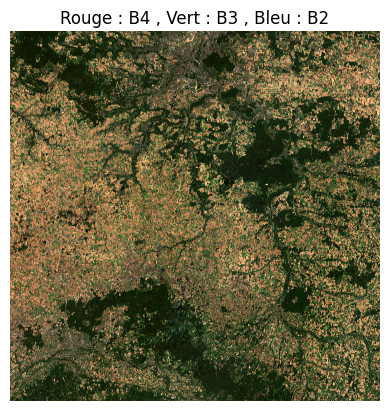

In [18]:
visu_img(image_pour_visu,[2,1,0])

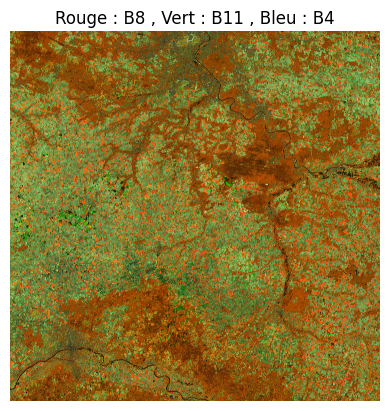

In [23]:
visu_img(image_pour_visu,[3,4,2])

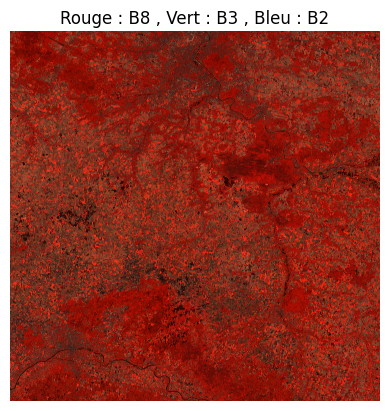

In [24]:
visu_img(image_pour_visu,[3,1,0])

## Statistiques radiométriques des bandes

In [25]:
def listvalband(band):
    im = []

    for fp in folder_paths:
        glob_path = join(fp, f"*{band}.tif")
        matches = glob.glob(glob_path)
        if not matches:
            continue

        with rasterio.open(matches[0]) as src:
            im.append(src.read(1).ravel())

    return np.concatenate(im)

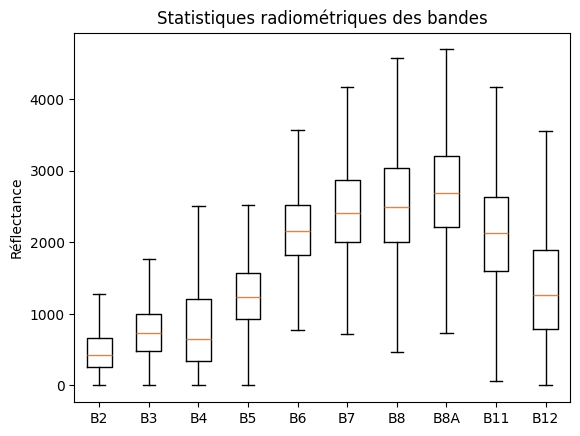

In [26]:
allbands = ["B2","B3","B4","B5","B6","B7","B8","B8A","B11","B12"]

data = [listvalband(band) for band in allbands] 

plt.boxplot(data, showfliers=False)  # showfliers=False Trop de valeurs ectrêmes sinon étant donnée que nous avons plus de 300 000 000 de valeurs pour chaque bande
plt.xticks(range(1, len(allbands)+1), allbands)
plt.ylabel("Réflectance")
plt.title("Statistiques radiométriques des bandes")
plt.show()

## Normalisation des images

In [27]:
#On normalise les images en faisant la variable centrée réduite de toutes les images de même bande
#Pour accélérer le calcul qui prend plusieurs minutes avec np, on utilise un tensor chargé sur le gpu
with torch.no_grad():
    images_tensor=torch.from_numpy(images).type(torch.float32).to(torch.device("cuda"))
    means=images_tensor.mean(axis=(0,2,3))
    stds=images_tensor.std(axis=(0,2,3))
    images_tensor.subtract_(means[None,:, None, None]).divide_(stds[None,:,None, None]) #les méthodes finissant par _ sont des inplaces en torch
                                                                            #ici cela nous permet d'économiser beaucoup de RAM en ne créant pas un deuxième tensor pour stocker le résultat
images_cr=images_tensor.cpu().numpy() #on repasse les images en array sur le cpu.                                                                            

## Rasterisation de CLC

In [32]:
#On crée une fonction qui crée une version rasterizée et de même format du clc pour chaque image et qui ne garde que le premier numéro de la classe clc
def get_rastClc(bounds, clc, nom_classe="Code_18", resolution=10):
    height=int((bounds.top-bounds.bottom)/resolution)
    width=int((bounds.right-bounds.left)/resolution)
    transform=rasterio.transform.from_bounds(*bounds, width, height)
    #on crée un generator python, qui calcule les valeurs à la volée plutôt que de les copier en ram
    shapes=((geom,int(classe[0])) for geom, classe in zip(clc.geometry, clc[nom_classe]))

    #on utilise la rasterization de rasterio
    rastClc=rasterio.features.rasterize(
        shapes=shapes,
        out_shape=(height,width),
        transform=transform,
        fill=0
    )

    return rastClc

In [33]:
clc_rasters=[]
for i in range(len(bounds)):
    clc_rasters.append(get_rastClc(bounds[i], clc32631))
clc_rasters=np.array(clc_rasters)

In [34]:
np.unique(clc_rasters[2])

array([1, 2, 3, 4, 5])

In [35]:
labels = [
    "Surfaces artificialisées",
    "Zones agricoles",
    "Forêts et milieux semi-naturels",
    "Zones humides",
    "Surfaces en eau"
]

colors = [
    "#e6004d", 
    "#ffffa8",  
    "#80ff00",  
    "#a6a6ff",  
    "#00ccf2"   
]

In [36]:
#pour accélérer la visualisation des rasters, on fait dessus un maxpool pour réduire leur résolution
rasters_pour_visu=torch.from_numpy(clc_rasters.copy())

In [37]:
clc_rasters.shape

(3, 10980, 10980)

In [38]:
with torch.no_grad():
    rasters_pour_visu=torch.from_numpy(clc_rasters.copy()).type(torch.float32).to(torch.device("cuda"))
    maxpool=nn.MaxPool2d(10)
    rasters_pour_visu=maxpool(rasters_pour_visu)
rasters_pour_visu=rasters_pour_visu.cpu().numpy()


(np.float64(-0.5), np.float64(1097.5), np.float64(1097.5), np.float64(-0.5))

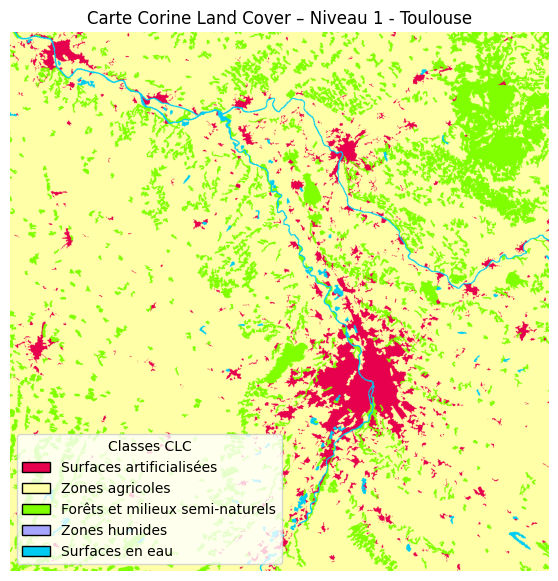

In [39]:
cmap = ListedColormap(colors)
boundsCarto = np.arange(0.5, 6.5, 1)
norm = BoundaryNorm(boundsCarto, cmap.N)
fig, ax = plt.subplots(figsize=(7, 7))
legend_elements = [Patch(facecolor=colors[i], edgecolor="black", label=labels[i]) for i in range(5)]
ax.legend(handles=legend_elements,title="Classes CLC",loc="lower left",frameon=True)
img = ax.imshow(rasters_pour_visu[0,:,:], cmap=cmap, norm=norm)
ax.set_title("Carte Corine Land Cover – Niveau 1 - Toulouse")
ax.axis("off")

(np.float64(-0.5), np.float64(1097.5), np.float64(1097.5), np.float64(-0.5))

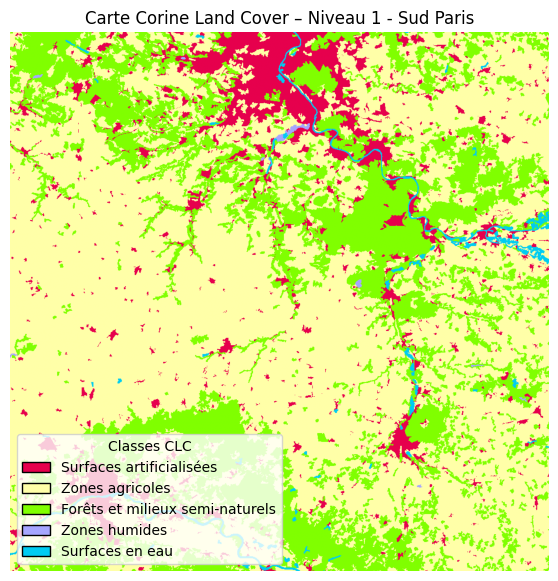

In [40]:
cmap = ListedColormap(colors)
boundsCarto = np.arange(0.5, 6.5, 1)
norm = BoundaryNorm(boundsCarto, cmap.N)
fig, ax = plt.subplots(figsize=(7, 7))
legend_elements = [Patch(facecolor=colors[i], edgecolor="black", label=labels[i]) for i in range(5)]
ax.legend(handles=legend_elements,title="Classes CLC",loc="lower left",frameon=True)
img = ax.imshow(rasters_pour_visu[1,:,:], cmap=cmap, norm=norm)
ax.set_title("Carte Corine Land Cover – Niveau 1 - Sud Paris")
ax.axis("off")

(np.float64(-0.5), np.float64(1097.5), np.float64(1097.5), np.float64(-0.5))

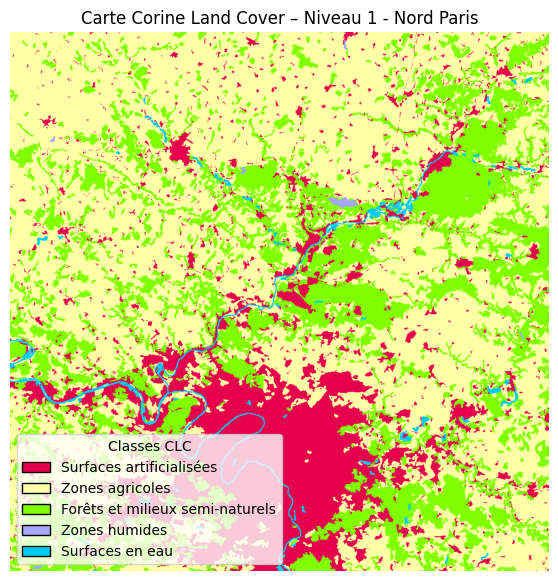

In [41]:
cmap = ListedColormap(colors)
boundsCarto = np.arange(0.5, 6.5, 1)
norm = BoundaryNorm(boundsCarto, cmap.N)
fig, ax = plt.subplots(figsize=(7, 7))
legend_elements = [Patch(facecolor=colors[i], edgecolor="black", label=labels[i]) for i in range(5)]
ax.legend(handles=legend_elements,title="Classes CLC",loc="lower left",frameon=True)
img = ax.imshow(rasters_pour_visu[2,:,:], cmap=cmap, norm=norm)
ax.set_title("Carte Corine Land Cover – Niveau 1 - Nord Paris")
ax.axis("off")

## Création patches

In [13]:
cote_patch=512
ignore_border=20 #paramètre pour la gestion des effets de bord
                #indique le nombre de pixels au bord de chaque patch dont les prédictions ne seront pas prises en compte
                #implique qu'il faut qu'il y ait du recouvrement entre nos patchs d'entraînement, car sinon, toute une partie du jeu de donnée n'est jamais prise en compte
num_patch_by_dim=images.shape[2]//(cote_patch-2*ignore_border)

#on crée un array qui contient toutes les coordonnées du bord supérieur droit de chaque patch
im, xx, yy=np.meshgrid(np.arange(0,3), np.arange(0,num_patch_by_dim), np.arange(0,num_patch_by_dim))
xx=np.where((xx!=0) & (yy!=0), xx*(cote_patch-2*ignore_border), 0)
yy=np.where((xx!=0) & (yy!=0), yy*(cote_patch-2*ignore_border), 0)
patch_coord=np.column_stack([im.ravel(), xx.ravel(), yy.ravel()])

In [15]:
#on tire au hasard le jeu d'entraînement, de test et de validation à partir de patch_coord
np.random.shuffle(patch_coord)
entrainement=patch_coord[500:]
test=patch_coord[0:250]
validation=patch_coord[250:500]

In [16]:
#on veut sauvegarder les fichiers dans les bons dossiers
#sauvegarder en float32 les images centrées réduites et en uint8 les clc pour économiser de la place.

def export_patches(out_path, picked_coords, images_cr):
    im_dir=join(out_path,"images")
    label_dir=join(out_path, "labels")

    for i, coords in enumerate(picked_coords):
        im_idx,l,c=coords
        np.save(join(im_dir, f"{i}.npy"), (images_cr[im_idx, :,l:l+cote_patch, c:c+cote_patch]).astype(np.float32))
        np.save(join(label_dir, f"{i}.npy"), (clc_rasters[im_idx, l:l+cote_patch, c:c+cote_patch]).T.astype(np.uint8)) #en analysant les résultats, j'ai réalisé que malgré la transformation, clc était en lat lon alors qu'il devrait être en lon lat. Je transpose donc les labels pour qu'ils soient en lon lat.

In [17]:
#jeu d'entrainement
out_path=r"data\entrainement"

export_patches(out_path, entrainement, images_cr)

In [18]:
#jeu de test
out_path=r"data\test"

export_patches(out_path, test, images_cr)

In [19]:
#jeu de validation
out_path=r"data\validation"

export_patches(out_path, validation, images_cr)

## Analyse de la distribution des classes

In [143]:
def get_jeu_complet(fp):
    labels_folder=join(fp, "labels")
    labels_p=os.listdir(labels_folder)
    labels=[]
    for label_p in labels_p:
        labels.append(np.load(join(labels_folder, label_p)))
    labels=np.array(labels)
    return labels

      effectif  proportion
1   36648373.0    0.128613
2  192004440.0    0.673817
3   53578600.0    0.188028
4     133169.0    0.000467
5    2585946.0    0.009075


Text(0.5, 1.0, "proportions des classes dans le jeu d'entrainement")

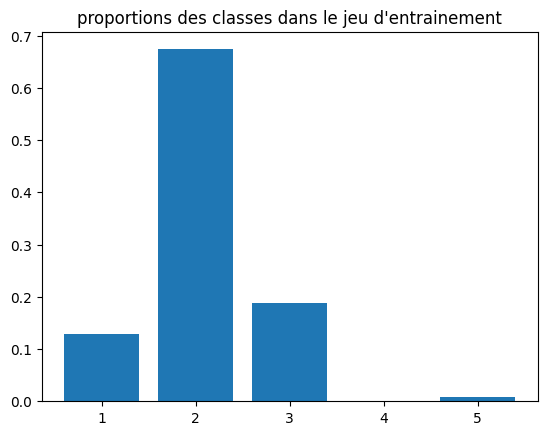

In [158]:
#distributions des classes du jeu d'entrainement

jeu=get_jeu_complet(r"data\entrainement")
classes, effectif=np.unique(jeu, return_counts=True)
distrib_df=pd.DataFrame(np.column_stack([effectif, effectif/jeu.size]), index=classes, columns=["effectif", "proportion"])
print(distrib_df)
plt.bar(classes, effectif/jeu.size)
plt.title("proportions des classes dans le jeu d'entrainement")

     effectif  proportion
1   9003925.0    0.137389
2  43134725.0    0.658184
3  12812568.0    0.195504
4     44836.0    0.000684
5    539946.0    0.008239


Text(0.5, 1.0, 'proportions des classes dans le jeu de validation')

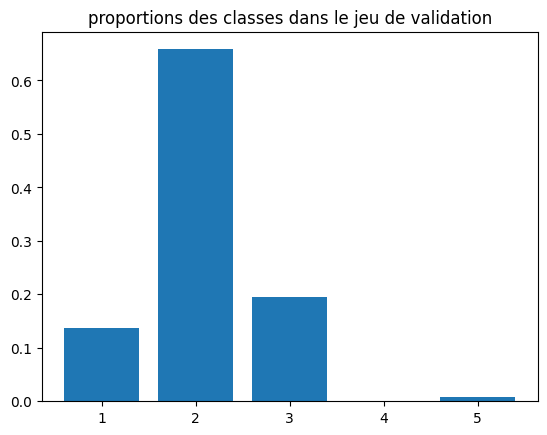

In [159]:
#distributions des classes du jeu de validation

jeu=get_jeu_complet(r"data\validation")
classes, effectif=np.unique(jeu, return_counts=True)
distrib_df=pd.DataFrame(np.column_stack([effectif, effectif/jeu.size]), index=classes, columns=["effectif", "proportion"])
print(distrib_df)
plt.bar(classes, effectif/jeu.size)
plt.title("proportions des classes dans le jeu de validation")

     effectif  proportion
1   7422101.0    0.113252
2  44088489.0    0.672737
3  13400563.0    0.204476
4     46514.0    0.000710
5    578333.0    0.008825


Text(0.5, 1.0, 'proportions des classes dans le jeu de test')

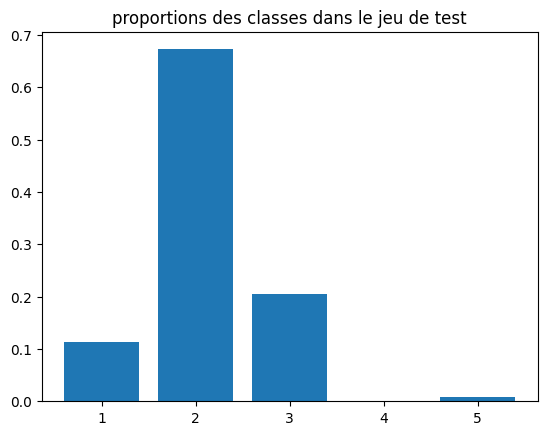

In [160]:
#distributions des classes du jeu de test

jeu=get_jeu_complet(r"data\test")
classes, effectif=np.unique(jeu, return_counts=True)
distrib_df=pd.DataFrame(np.column_stack([effectif, effectif/jeu.size]), index=classes, columns=["effectif", "proportion"])
print(distrib_df)
plt.bar(classes, effectif/jeu.size)
plt.title("proportions des classes dans le jeu de test")

## export tirages

In [63]:
tirages_folder=r"data\tirages"

np.save(join(tirages_folder, "entrainement"), entrainement)
np.save(join(tirages_folder, "test"), test)
np.save(join(tirages_folder, "validation"), validation)

## Vérification appariement labels / images

In [43]:
def check_dataset(dir, idx=-1): #fonction pour tester le bon appariement des labels et images
    im_dir=join(dir,"images")
    label_dir=join(dir, "labels")
    num_files=len(os.listdir(im_dir))
    if idx==-1:
        idx=random.randint(0,num_files)
    print(idx)
    file=f"{idx}.npy"
    im=np.load(join(im_dir,file))
    lab=np.load(join(label_dir, file))
    return np.transpose(im, (2,1,0))[:,:,2::-1], lab

74


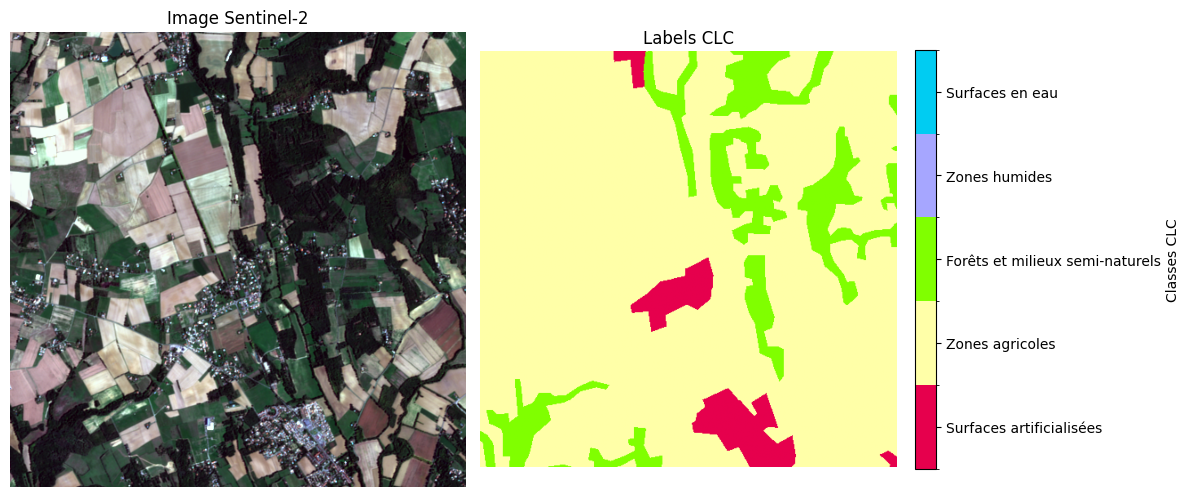

In [45]:
img, lab=check_dataset(r"data\validation")
img_clipped = img.astype(np.float32)
for c in range(3):
    low, high = np.percentile(img[:, :, c], [1, 99])
    img_clipped[:, :, c] = np.clip(img_clipped[:, :, c], low, high)

img_clipped = (img_clipped - img_clipped.min()) / (img_clipped.max() - img_clipped.min())

fig, axes = plt.subplots(1, 2, figsize=(12, 6))

axes[0].imshow(img_clipped)
axes[0].set_title("Image Sentinel-2")
axes[0].axis("off")


im_lab = axes[1].imshow(lab, cmap=cmap, norm=norm)
axes[1].set_title("Labels CLC")
axes[1].axis("off")

cbar = plt.colorbar(
    im_lab,
    ax=axes[1],
    orientation="vertical",
    ticks=np.arange(1, 6),
    fraction=0.046,
    pad=0.04
)

cbar.ax.set_yticklabels(labels)
cbar.set_label("Classes CLC")

plt.tight_layout()
plt.show()

# TP2  
On veut à présent entraîner un U-Net sur nos données

## On implémente les datasets et dataloaders adaptés à notre jeu de données

In [26]:
#On ajoute des rotations, des flips et du bruit gaussien pour l'augmentation de données
#On utilise les fonctions d'albumentations qui gèrent la nécessité d'appliquer les mêmes transformations spatiales à mask et labels
class s2_dataset(Dataset):
    def __init__(self, root_dir):
        super().__init__()
        self.root_dir=root_dir
        self.image_dir=join(self.root_dir, "images")
        self.label_dir=join(self.root_dir, "labels")
        self.label_files=os.listdir(self.label_dir)
        self.image_files=os.listdir(self.image_dir)
        # self.transform=A.Compose([
        #     # A.Rotate(p=0.8, mask_value=-999), on ne peut pas utiliser rotate avec le recouvrement
        #     A.HorizontalFlip(),
        #     A.GaussNoise(std_range=(0,0.15)), #params par défaut : p=0.5, mean=0, variance varie entre 20% et 44% du max de l'image
        #     A.ToTensorV2()
        # ])

    def __len__(self):
        return len(self.image_files)
    
    #On définit la fonction getitem pour renvoyer les éléments correspondants dans les files
    def __getitem__(self, idx):
        label_file=join(self.label_dir, self.label_files[idx])
        image_file=join(self.image_dir, self.image_files[idx])
        label=torch.from_numpy(np.load(label_file).T).type(torch.long)
        image=torch.from_numpy(np.load(image_file))
        # image=np.transpose(np.load(image_file), (1,2,0))
        # transformed=self.transform(image=image, mask=label) #rotate fait par défaut une interpolation linéaire pour les images et plus proche voisin pour les masques
        # return transformed["image"], transformed["mask"].type(torch.long)
        return image, label

In [27]:
#instanciations dataset
train_dataset=s2_dataset(r"data\entrainement")
test_dataset=s2_dataset(r"data\test")
validation_dataset=s2_dataset(r"data\validation")

#On construit également les dataloaders:
batch_size=8

train_dataloader=DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
test_dataloader=DataLoader(test_dataset, batch_size=batch_size, shuffle=True)
validation_dataloader=DataLoader(validation_dataset, batch_size=batch_size, shuffle=True)

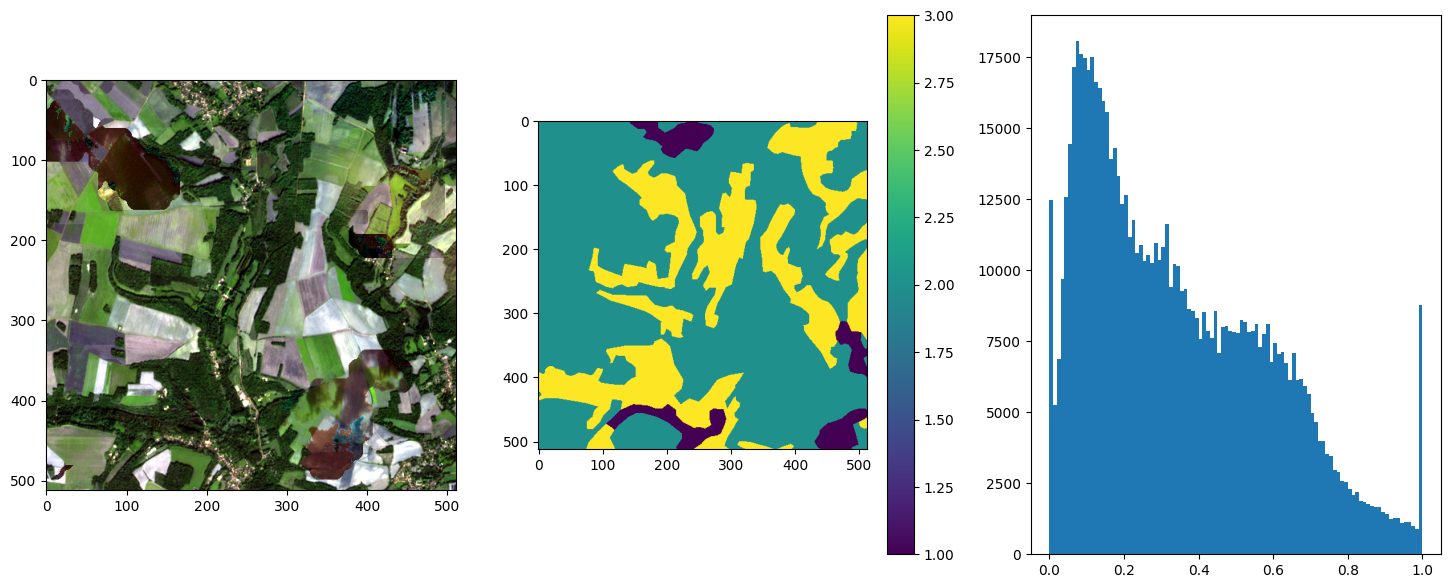

In [31]:
img,mask=train_dataset[500]
img=img.permute([1,2,0])[:,:,:3].numpy()
img=img.astype(np.float32)
for c in range(img.shape[-1]):
    low,high=np.percentile(img[:,:,c],[1,99])
    img[:,:,c]=np.clip(img[:,:,c], low,high)
    img[:,:,c]=img[:,:,c]-img[:,:,c].min()
    img[:,:,c]=img[:,:,c]*(1/img[:,:,c].max())


plt.figure(figsize=(18,7))
plt.subplot(1,3,1)
plt.imshow(img)
plt.subplot(1,3,2)
plt.imshow(mask)
plt.colorbar()
plt.subplot(1,3,3)
_=plt.hist(img.ravel(), bins=100)

## Architecture U-Net  
On veut maintenant constuire notre architecture U-Net.
On veut que l'encodeur utilise deux convolutions 3*3 successives avec à chaque fois batch norm et relu.
Le décodeur mobilisera upscaling Bilinear, concaténation avec les skip connections, convolution.
Enfin on output avec le bon nombre de classes via une convolution 1*1.

In [32]:
#Classe des doubles convolutions
class DoubleConv(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.doubleconv=nn.Sequential(
            nn.Conv2d(in_channels, out_channels, 3, padding=1), #on met un padding de 1 pour ne pas réduire les dimensions après la convolution.
            nn.BatchNorm2d(out_channels), #Out channels précise le nombre de canaux à traiter séparément pour la normalisatin.
            nn.ReLU(inplace=True), #ReLU est une fonction déjà définie, sans paramètres à tuner. On utilise inplace true parcequ'on connaît donc déjà sa dérivé.
                                    #aini, on n'a pas besoin de garder l'information du précédent tensor pour dériver car torch garde automatiquement un masque pour se souvenir des valeurs positives et négatives dont la dérivée est différente.
            nn.Conv2d(out_channels,out_channels, 3, padding=1), #On applique une seconde convolution, cette fois avec beaucoup plus de canaux en entrée.
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.doubleconv(x)

In [33]:
#Classe de la brique d'encodage : on applique un maxpool 2*2 puis on applique la double conv
class Down(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.down=nn.Sequential(
            nn.MaxPool2d(2),#On commence par le maxpool 2*2
            DoubleConv(in_channels, out_channels)
        )
    def forward(self, x):
        return self.down(x)

In [34]:
#Classe de la brique de décodage : on applique un upsample, on concatène avec la skip connection et on applique notre double conv
#On ne peut pas définir un sequential dans l'init, car on doit introduire le passage d'une skip connection dans le forward

class Up(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.upsample=nn.Upsample(scale_factor=2, mode="bilinear", align_corners=True) #aligner les corners sert à ne pas décaler les images après des upsample successifs, ce qui garantit qu'elles se concaténent bien avec la skip connection
                                                                                        #Le scale factor de 2 permet de faire un upsample inverse du maxpool 2*2
        self.doubleconv=DoubleConv(in_channels, out_channels)

    def forward(self, x, skip):
        upsampled=self.upsample(x)
        concatenated=torch.cat([upsampled, skip], dim=1) #On choisit bien la deuxième dimension pour stacker en canaux
        return self.doubleconv(concatenated)


In [35]:
#On définit notre classe de U-Net à partir de nos briques
#On encode jusqu'à arriver à des features maps 16*16 et on double le nombre de filtres à chaque étape de downsampling

class S2_segmentation_U_Net(nn.Module):
    def __init__(self, in_channels, nbr_classes, init):
        super().__init__()

        self.inc=DoubleConv(in_channels, init) #512*512

        self.down1=Down(init, init*2) #256
        self.down2=Down(init*2, init*4) #128
        self.down3=Down(init*4, init*8) #64
        self.down4=Down(init*8,init*16) #32
        self.down5=Down(init*16, init*32) #16

        self.up1=Up(init*32+init*16, init*16) #32*32 Le nombre de in channels correspond au nombre de channels d'entrée plus le nombre de channels de la skip connection, c'est à dire de l'output du down précédent
        self.up2=Up(init*16+init*8, init*8) #64
        self.up3=Up(init*8+init*4, init*4) #128
        self.up4=Up(init*4+init*2, init*2) #256
        self.up5=Up(init*2+init,init) #512

        self.outc=nn.Conv2d(init,nbr_classes,1)

    def forward(self, batch):
        x1=self.inc(batch)

        x2=self.down1(x1) #encoding
        x3=self.down2(x2)
        x4=self.down3(x3)
        x5=self.down4(x4)
        x6=self.down5(x5)

        x7=self.up1(x6,x5)
        x8=self.up2(x7, x4)
        x9=self.up3(x8,x3)
        x10=self.up4(x9,x2)
        x11=self.up5(x10,x1)

        x12=self.outc(x11)
        
        return x12

## Training et Test Loops

In [50]:
#On implémente nos boucles d'entraînement et de test
#On utilise le stocastique gradient descent et la cross entropy
def training_loop(dataloader, model, loss_fn, optimizer, ignore_border=20):
    model.train() #On met en mode train pour utiliser les stats par batch de batchnorm2d pour la normalisation
    device=torch.device("cuda" if torch.cuda.is_available() else "cpu")
    loss=0
    correct=0
    size=len(dataloader.dataset)
    batch_num=len(dataloader)
    scaler=torch.amp.GradScaler("cuda")

    for i, batch in enumerate(dataloader):
        images, labels=batch
        images=images.to(device)
        labels=labels.to(device).type(torch.long)
        # with torch.amp.autocast("cuda"): #auto cast permet de passer en float 16 quand c'est possible pour augmenter le nombre de batches
        #     pred=model(images)
        #     pred=pred[:,:,ignore_border:-ignore_border,ignore_border:-ignore_border]
        #     labels=labels[:,ignore_border:-ignore_border,ignore_border:-ignore_border]
        #     loss=loss_fn(pred, labels)
        # scaler.scale(loss).backward()
        # scaler.step(optimizer)
        # scaler.update()

        pred=model(images)
        pred=pred[:,:,ignore_border:-ignore_border,ignore_border:-ignore_border]
        labels=labels[:,ignore_border:-ignore_border,ignore_border:-ignore_border]
        loss=loss_fn(pred, labels)

        loss.backward()
        optimizer.step()
        
        optimizer.zero_grad()
        # print(f"batch : {i}")

        loss+=loss_fn(pred, labels).item()
        correct+= (pred.argmax(1) == labels).type(torch.float).sum().item()

    mean_loss=loss/batch_num
    global_accuracy=correct/(size*512*512)
    return mean_loss, global_accuracy

def test_loop(dataloader, model, loss_fn, ignore_border=20):
    model.eval() #On met en mode éval pour utiliser les stats cummulées des batchs, enregistrées par les couches batchnorm2d
    device=torch.device("cuda" if torch.cuda.is_available() else "cpu")

    size=len(dataloader.dataset)
    batch_num=len(dataloader)

    correct=0
    test_loss=0
    with torch.no_grad(): #on désactive le calcul des gradients
        for images, labels in dataloader:
            images=images.to(device)
            labels=labels.to(device).type(torch.long)
            pred=model(images)
            pred=pred[:,:,ignore_border:-ignore_border,ignore_border:-ignore_border]
            labels=labels[:,ignore_border:-ignore_border,ignore_border:-ignore_border]
            test_loss+=loss_fn(pred, labels).item()
            correct+= (pred.argmax(1) == labels).type(torch.float).sum().item()
    
    mean_loss=test_loss/batch_num
    global_accuracy=correct/(size*512*512)
    return mean_loss, global_accuracy

## Entraînement

In [51]:
#On implémente l'entraînement et le test

#hyper paramètres
ignore_border=20 #paramètre qui doit être le même que celui utilisé pour la fabrication des patches
nbr_bandes=4
nbr_classes=6
lr=1e-3
device=torch.device("cuda" if torch.cuda.is_available() else "cpu")
init_channels=16

In [52]:
#instanciations
s2_segmentation_model=S2_segmentation_U_Net(nbr_bandes, nbr_classes, init_channels)
s2_segmentation_model.to(device)

loss_fn=nn.CrossEntropyLoss(ignore_index=0)
optimizer=torch.optim.Adam(s2_segmentation_model.parameters(), lr=lr)

In [54]:
train_stats=[]
test_stats=[]
min_loss=-1

In [55]:
epochs=20

In [57]:
for epoch in range(epochs):
    training_loss, training_accuracy=training_loop(train_dataloader, s2_segmentation_model, loss_fn, optimizer)

    test_loss, test_accuracy=test_loop(test_dataloader, s2_segmentation_model, loss_fn)

    if test_loss<=min_loss or min_loss==-1:
        backup={k:v.clone() for k, v in s2_segmentation_model.state_dict().items()}
        min_loss=test_loss
    train_stats.append((training_loss, training_accuracy))
    test_stats.append((test_loss, test_accuracy))
    print(f"epoch {epoch} ; train_accuracy : {training_accuracy} ; train_loss : {training_loss} ; test_loss : {test_loss} ; test_accuracy : {test_accuracy}")

epoch 0 ; train_accuracy : 0.7476907570425698 ; train_loss : 0.0071331229992210865 ; test_loss : 0.4917436293326318 ; test_accuracy : 0.6998016662597656
epoch 1 ; train_accuracy : 0.7494310240407767 ; train_loss : 0.0036795898340642452 ; test_loss : 0.31568849785253406 ; test_accuracy : 0.763501693725586
epoch 2 ; train_accuracy : 0.760417780310272 ; train_loss : 0.004747126717120409 ; test_loss : 0.2862953613512218 ; test_accuracy : 0.7705717010498047
epoch 3 ; train_accuracy : 0.7662098945119343 ; train_loss : 0.003146654926240444 ; test_loss : 0.3773803315125406 ; test_accuracy : 0.7637428283691406
epoch 4 ; train_accuracy : 0.7711544475537873 ; train_loss : 0.0050544701516628265 ; test_loss : 0.23357842955738306 ; test_accuracy : 0.7774305877685547
epoch 5 ; train_accuracy : 0.7750076462395605 ; train_loss : 0.0029671599622815847 ; test_loss : 0.2329001766629517 ; test_accuracy : 0.7753237609863282
epoch 6 ; train_accuracy : 0.775687602866979 ; train_loss : 0.0032186186872422695 ; 

In [59]:
test_stats

[(0.4917436293326318, 0.6998016662597656),
 (0.31568849785253406, 0.763501693725586),
 (0.2862953613512218, 0.7705717010498047),
 (0.3773803315125406, 0.7637428283691406),
 (0.23357842955738306, 0.7774305877685547),
 (0.2329001766629517, 0.7753237609863282),
 (0.2154887467622757, 0.7822954406738282),
 (0.20702431839890778, 0.7841682281494141),
 (0.20848611276596785, 0.7842782745361329),
 (0.20102179422974586, 0.7862948455810547),
 (0.20857091434299946, 0.7840660705566406),
 (0.2086671837605536, 0.7845208435058594),
 (0.215565565507859, 0.7825953674316406),
 (0.33447244856506586, 0.7644655609130859),
 (0.18919112090952694, 0.789162109375),
 (0.18972980044782162, 0.7898249816894531),
 (0.1949432387482375, 0.7902660369873047),
 (0.18638854078017175, 0.791125),
 (0.18445506994612515, 0.7911930236816406),
 (0.2666259231045842, 0.7789759216308594)]

## Graphes Loss et Précision

Text(0.5, 1.0, "Valeurs de la cross-entropy loss pour le jeu d'entraînement et de test en fonction des époques")

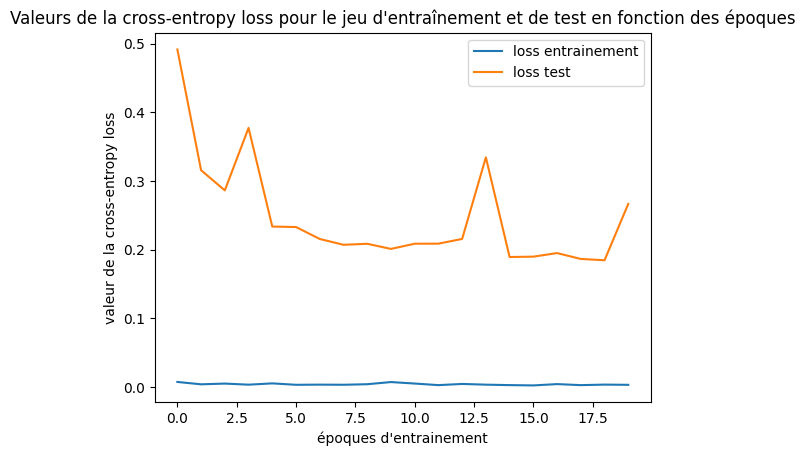

In [140]:
plt.plot(range(len(train_stats)), np.array(train_stats)[:,0], label="loss entrainement")
plt.plot(range(len(test_stats)), np.array(test_stats)[:,0], label="loss test")
plt.legend()
plt.xlabel("époques d'entrainement")
plt.ylabel("valeur de la cross-entropy loss")
plt.title("Valeurs de la cross-entropy loss pour le jeu d'entraînement et de test en fonction des époques")

Text(0.5, 1.0, "Valeurs de la précision globale pour le jeu d'entraînement et de test en fonction des époques")

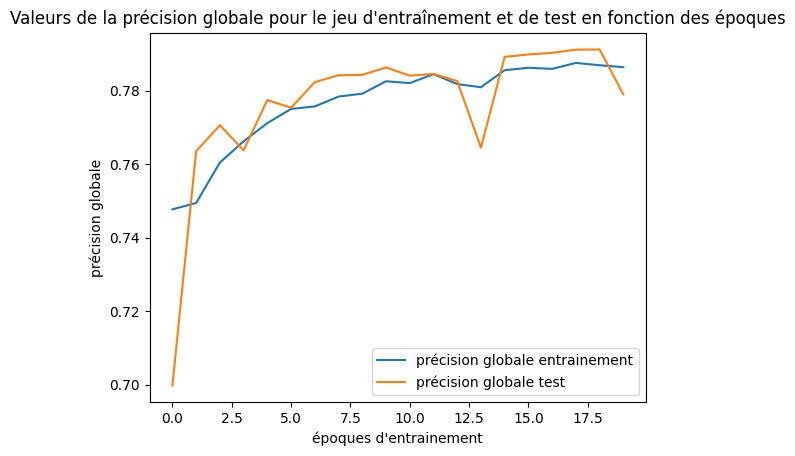

In [142]:
plt.plot(range(len(train_stats)), np.array(train_stats)[:,1], label="précision globale entrainement")
plt.plot(range(len(test_stats)), np.array(test_stats)[:,1], label="précision globale test")
plt.legend()
plt.xlabel("époques d'entrainement")
plt.ylabel("précision globale")
plt.title("Valeurs de la précision globale pour le jeu d'entraînement et de test en fonction des époques")

## Export modèle

In [75]:
model_folder=r"modeles\modele3"

In [76]:
torch.save(backup, join(model_folder, "best_loss.pth"))

In [77]:
torch.save(s2_segmentation_model.state_dict(), join(model_folder, "last_epoch.pth"))

In [87]:
train_stats=[(loss.item(), accuracy) for (loss, accuracy) in train_stats]

In [88]:
np.save(join(model_folder, "test_stats"),np.array(test_stats))
np.save(join(model_folder, "training_stats"), np.array(train_stats))

# TP3

# Inférence

## instanciation du modèle à partir des poinds entrainés

In [92]:
model_pour_inf=S2_segmentation_U_Net(in_channels=4, nbr_classes=6, init=16)

In [93]:
model_weights= torch.load(r"modeles\modele3\best_loss.pth")

In [94]:
model_pour_inf.load_state_dict(model_weights)

<All keys matched successfully>

In [95]:
model_pour_inf=model_pour_inf.to(torch.device("cuda"))

## implémentation dataset pour inférence

In [96]:
#datset pour l'inférence

class inference_dataset(torch.utils.data.Dataset):
    def __init__(self, image, ignore_border=20, cote_patch=512): #image doit être un numpy sur cpu au format H, W, C
        super().__init__()

        self.image=image
        self.cote_patch=cote_patch
        self.ignore_border=ignore_border
        
        height, width, _ = image.shape
        num_patch_yy, num_patch_xx=(height//(cote_patch-2*ignore_border), width//(cote_patch-2*ignore_border))
        self.num_patch_yy=num_patch_yy
        self.num_patch_xx=num_patch_xx
        
        #On commence par récupérer les coordonnées de chaque bord supérieur gauche de patche
        xx, yy = np.meshgrid(range(num_patch_xx), range(num_patch_yy))
        xx = xx * (cote_patch - 2*ignore_border)
        yy = yy * (cote_patch - 2*ignore_border)
        self.patch_coords=np.column_stack([xx.ravel(), yy.ravel()])

        self.transform=torchvision.transforms.ToTensor()

    def __len__(self):
        return len(self.patch_coords)

    def __getitem__(self, idx):
        coord=self.patch_coords[idx, :]
        patch=self.image[coord[1] : coord[1]+self.cote_patch, coord[0] : coord[0] + self.cote_patch, :]
        return self.transform(patch)

## Récupération et Normalisation des images pour inférence et instanciations datasets / dataloaders

In [97]:
def build_image(path, bandes):
    img, _, _ = get_s2(path, bandes)
    return np.transpose(img, [1,2,0])

In [98]:
def visu(img):
    img=img.copy().astype(np.float32)
    for c in range(img.shape[-1]):
        low, high = np.percentile(img[:,:,c], [1,99])
        img[:,:,c]=np.clip(img[:,:,c], low, high)
        img[:,:,c]= img[:,:,c]-img[:,:,c].min()
        img[:,:,c] = img[:,:,c] * (1/img[:,:,c].max())
    return img

In [99]:
imgs_paths= [
    r"data\input\lacleman",
    r"D:\Documents\repo_dl\tp_deep\data\input\SENTINEL2X_20251015-000000-000_L3A_T31TCJ_C.osm\SENTINEL2X_20251015-000000-000_L3A_T31TCJ_C_V4-0",
    r"D:\Documents\repo_dl\tp_deep\data\input\SENTINEL2X_20251015-000000-000_L3A_T31UDP_C.osm\SENTINEL2X_20251015-000000-000_L3A_T31UDP_C_V4-0",
    r"D:\Documents\repo_dl\tp_deep\data\input\SENTINEL2X_20251015-000000-000_L3A_T31UDQ_C.osm\SENTINEL2X_20251015-000000-000_L3A_T31UDQ_C_V4-0"
]

In [100]:
imgs=[build_image(path, ["B2", "B3", "B4", "B8"]) for path in imgs_paths]
images=np.array(imgs)

In [101]:
with torch.no_grad():
    images_tensor=torch.from_numpy(images).type(torch.float32).to(torch.device("cuda"))
    means=images_tensor.mean(axis=(0,1,2))
    stds=images_tensor.std(axis=(0,1,2))
    images_tensor.subtract_(means[None, None, None, :]).divide_(stds[None,None, None, :]) #les méthodes finissant par _ sont des inplaces en torch
                                                                            #ici cela nous permet d'économiser beaucoup de RAM en ne créant pas un deuxième tensor pour stocker le résultat
images_cr=images_tensor.cpu().numpy() #on repasse les images en array sur le cpu.                               

In [102]:
datasets=[inference_dataset(images_cr[i, :,:,:]) for i in range(len(images_cr))]

In [103]:
dataloaders=[torch.utils.data.DataLoader(dataset, batch_size=32) for dataset in datasets]

In [114]:
#Fonction qui n'est plus utilisée au final
def redim_batch(batch, target_size=32):
    diff=target_size-len(batch)
    if diff>0:
        fill_shape=(diff, *batch.shape[1:])
        fill_tensor=torch.full(fill_shape, -999, dtype=batch.dtype, device=batch.device)
        return torch.cat([batch,fill_tensor])
    return batch

## Inference Loop

In [104]:
def inference_loop(dataloader, model, device=torch.device("cuda")):
    with torch.no_grad():
        model.eval()
        dim_patch=dataloader.dataset.cote_patch-2*dataloader.dataset.ignore_border
        mosaique=torch.empty((
            len(dataloader.dataset), 
            dataloader.dataset.cote_patch-2*dataloader.dataset.ignore_border, 
            dataloader.dataset.cote_patch-2*dataloader.dataset.ignore_border)
            , device=device)
            
        for i, batch in enumerate(dataloader):
            batch=batch.to(device)
            pred=model(batch)
            pred=pred.argmax(1)
            pred=pred[:,dataloader.dataset.ignore_border:-dataloader.dataset.ignore_border, dataloader.dataset.ignore_border:-dataloader.dataset.ignore_border]
            pred=pred.reshape(-1, *pred.shape[1:]) #on passe du format num_batch, batch__size, h, w à num_images, H, W
            mosaique[i*dataloader.batch_size:i*dataloader.batch_size+len(pred)]=pred
        mosaique=mosaique.reshape((
            dataloader.dataset.num_patch_yy, 
            dataloader.dataset.num_patch_xx, 
            dataloader.dataset.cote_patch-2*dataloader.dataset.ignore_border, 
            dataloader.dataset.cote_patch-2*dataloader.dataset.ignore_border))
        mosaique = mosaique.permute(0, 2, 1, 3)

        # assemblage final
        mosaique = mosaique.reshape(dataloader.dataset.num_patch_yy*dim_patch, dataloader.dataset.num_patch_xx*dim_patch)
    return mosaique


## Affichage image et prédictions

In [105]:
def visu_labels(labels, agg=10):
    with torch.no_grad():
        maxpool=nn.MaxPool2d(agg)
        labels=maxpool(labels[None, :,:])
        return labels.cpu().numpy().squeeze()

In [106]:
def down_sample_s2(img, agg=10):
    with torch.no_grad():
        totensor=torchvision.transforms.ToTensor()
        img=totensor(img[:,:,:]).to(torch.device("cuda")).type(torch.float16)
        avgpool=nn.AvgPool2d(agg)
        img=avgpool(img[None, :,:,:])
        img=img.permute([0,2,3,1])
        return img.cpu().numpy().squeeze()

In [ ]:
test_inference=inference_loop(dataloaders[0], model=model_pour_inf)

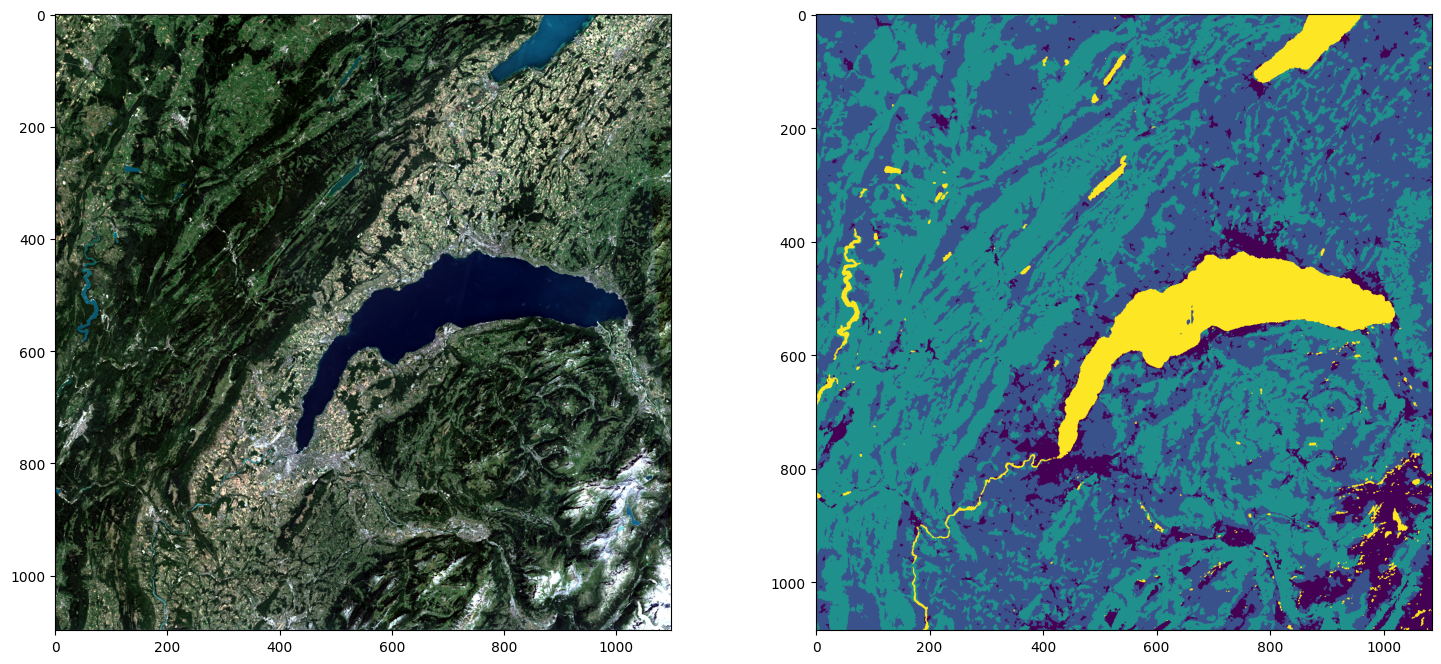

In [108]:
plt.figure(figsize=(18,8))
plt.subplot(1,2,1)
plt.imshow(visu(down_sample_s2(imgs[0])[:,:,2::-1]))
plt.subplot(1,2,2)
plt.imshow(visu_labels(test_inference))

# Matrice de Confusion

## validation loop

In [109]:
def validation_loop(dataloader, model, ignore_border=20):
    model.eval() #On met en mode éval pour utiliser les stats cummulées des batchs, enregistrées par les couches batchnorm2d
    device=torch.device("cuda" if torch.cuda.is_available() else "cpu")

    size=len(dataloader.dataset)
    batch_num=len(dataloader)

    with torch.no_grad(): #on désactive le calcul des gradients
        for i, batch in enumerate(dataloader):
            images, labels= batch
            images=images.to(device)
            labels=labels.to(device).type(torch.long)
            pred=model(images)
            pred=pred[:,:,ignore_border:-ignore_border,ignore_border:-ignore_border]
            pred=pred.argmax(1)
            pred=pred.ravel()
            labels=labels[:,ignore_border:-ignore_border,ignore_border:-ignore_border].ravel()
            current=torch.column_stack([pred.ravel(), labels.ravel()])
            if i==0:
                mat_conf=current
            else:
                mat_conf=torch.cat([mat_conf, current], dim=0)


    return mat_conf

## création matrice de confusion

In [110]:
tst_mat_conf=validation_loop(validation_dataloader, model_pour_inf)

In [111]:
mat_conf_df=pd.DataFrame(torch.column_stack(tst_mat_conf.unique(return_counts=True, dim=0)).cpu().numpy(), columns=["prédit", "réf", "effectif"])

In [112]:
mat_conf_df

,prédit,réf,effectif
0,1,1,6343566
1,1,2,646606
2,1,3,167106
3,1,4,61
4,1,5,10287
5,2,1,955498
6,2,2,35297455
7,2,3,1468512
8,2,4,8971
9,2,5,49638


In [113]:
mat_conf_df=mat_conf_df.pivot_table(index="prédit", columns="réf", values="effectif")

## Affichage Matrice de confusion, Calcul de précisions, rappels et FScore

In [128]:
mat_conf_df.loc[4]=0

In [123]:
mat_conf_df.sort_index(inplace=True)

In [182]:
#Matrice de confusion en effectif
mat_conf_df.columns.name="classe de référence"
mat_conf_df.index.name="classe prédite"
mat_conf_df

classe de référence,1,2,3,4,5
classe prédite,,,,,
1,6343566.0,646606.0,167106.0,61.0,10287.0
2,955498.0,35297455.0,1468512.0,8971.0,49638.0
3,325020.0,594468.0,9230455.0,22393.0,20728.0
4,0.0,0.0,0.0,0.0,0.0
5,66469.0,58508.0,45950.0,6709.0,377600.0


In [162]:
mat_conf_arr=mat_conf_df.to_numpy()

In [181]:
#Matrice de confusion en pourcentage en ligne
mat_conf_pourcent=pd.DataFrame((mat_conf_arr/(mat_conf_arr.sum(axis=1)[:, None]))*100, columns=[1,2,3,4,5], index=[1,2,3,4,5])
mat_conf_pourcent.columns.name="classe de référence"
mat_conf_pourcent.index.name="classe prédite"
mat_conf_pourcent

C:\Users\Formation\AppData\Local\Temp\ipykernel_19592\3710914362.py:2: RuntimeWarning: invalid value encountered in divide
  mat_conf_pourcent=pd.DataFrame((mat_conf_arr/(mat_conf_arr.sum(axis=1)[:, None]))*100, columns=[1,2,3,4,5], index=[1,2,3,4,5])


classe de référence,1,2,3,4,5
classe prédite,,,,,
1,88.503027,9.021202,2.331400,0.000851,0.143520
2,2.529106,93.428761,3.887001,0.023745,0.131387
3,3.188639,5.832083,90.556235,0.219689,0.203354
4,NaN,NaN,NaN,NaN,NaN
5,11.971306,10.537501,8.275760,1.208315,68.007118


In [130]:
mat_conf_arr=mat_conf_df.to_numpy()

bien_predits=np.sum(np.identity(len(mat_conf_arr))*mat_conf_arr, axis=0)

precisions=bien_predits/np.sum(mat_conf_arr, axis=1)
rappels=bien_predits/np.sum(mat_conf_arr, axis=0)

fscore=np.nanmean(2*precisions*rappels/(precisions+rappels))

C:\Users\Formation\AppData\Local\Temp\ipykernel_19592\3971013850.py:5: RuntimeWarning: invalid value encountered in divide
  precisions=bien_predits/np.sum(mat_conf_arr, axis=1)


In [131]:
precisions

array([0.88503027, 0.93428761, 0.90556235,        nan, 0.68007118])

In [132]:
rappels

array([0.82485174, 0.96448942, 0.84589769, 0.        , 0.82399897])

In [133]:
fscore

np.float64(0.8557231991509182)